# Lorehaven pricing forecast

This notebook forecasts **revenue per customer** and **member count** for the next four seasons (winter to fall 2020) under the prices and discounts you choose.

**How to use it**

1. Change any of the four numbers under **Your pricing choices**, and pick an advertising backdrop if you like.
2. Run the whole notebook (*Run All*). It takes about a minute.
3. Read the result under **The forecast**. It is always compared with today's policy.

Nothing else needs editing.

## What this forecast assumes

The difference between two settings is more reliable than either number on its own.

* **Advertising repeats a past year.** By default each customer sees the ads they saw in the same season of 2019. `AD_BACKDROP` can swap in another past year, or the lightest or heaviest season seen at each time of year (table under **Setup**). This holds fixed both the marketing plan and **how spend turns into each customer's ad exposure**, so it is a backdrop, not a spend lever: the tool cannot value a change in marketing spend.
* **Prices do not change who sees ads.** Exposure stays the same whatever the prices.
* **Customers respond to price as in 2017–2019.** The response comes from Lorehaven's randomized discounts, so it is cause and effect.
* **Five cut regions only** (357,686 customers). Panem kept \$15 with no offers, so there is no price response to learn there.
* **Starts from real membership at the end of fall 2019** (128,602 members). Each later season builds on the forecast, not on real results.
* **The customer base is fixed.** No one arrives or leaves the market; only membership changes.
* **Your settings give every discount eligible customer the same discount.**
* **Prices stay between \$7 and \$15**, the range ever charged. A caution prints when a setting goes past what was tried.
* **Four more seasons are run for context only,** to show whether a setting's lead holds once the member base adjusts.
* **Revenue, not profit.** Serving and advertising costs are not included.

## Your pricing choices

They apply to all four seasons. No price may go below \$7 or above \$15, the range that has actually been charged.

In [1]:
BASE_PRICE = 12          # list price for one season, $10 to $15            (today: 12)
JOINING_DISCOUNT = 5     # $ off the first season for non-members who get an offer, 0 to 5   (today: $1-$5 at random)
SHARE_OFFERED = 25       # % of non-members who get that offer each season, 0 to 100         (today: 25)
MEMBER_DISCOUNT = 1      # $ off every season after the first, 0 to 5                        (today: $1-$5 at random, re-drawn each season)

AD_BACKDROP = 'heaviest'   # advertising to assume: 'like 2017', 'like 2018', 'like 2019', 'lightest' or 'heaviest'

**Advertising backdrop.** Joining depends heavily on how much advertising people hear, so the forecast needs an assumption. `'like 2019'` repeats last year. `'lightest'` and `'heaviest'` take the season with the least or most advertising seen at each time of year, to bracket the forecast. The table under **Setup** shows every past season.

## Setup

In [2]:
import helper.tools_utils as tu

ctx = tu.load(AD_BACKDROP)

Ready: 357,686 customers in five regions, 128,602 of them members in Fall 2019.
Advertising backdrop 'heaviest': ads copied from Win 2019, Spr 2017, Sum 2018, Fall 2019.


### Advertising in past seasons

"Heavily exposed" is the share of customers who heard and saw a lot of ads that season (podcast listens × social impressions above 80), the level at which joining jumps. Spend is the planned budget, shown for reference only: the tool does not turn spend into results. "Used now" marks the seasons your backdrop copies. To change it, edit `AD_BACKDROP` at the top and run all again.

In [3]:
tu.ad_menu(ctx)

## The forecast

In [4]:
mine = tu.run(ctx, BASE_PRICE, JOINING_DISCOUNT, SHARE_OFFERED, MEMBER_DISCOUNT)

Your choices: $12 base price; $5 off the first season for 25% of non-members (they pay $7); $1 off for members (they pay $11).

Over the next four seasons each customer brings in $17.49,
and 151,289 are members by Fall 2020.

Compared with today's policy (a random $1-$5 off, re-drawn every season): $2.50 more per customer (+16.7%), and 2,948 fewer members.
In total: $6,254,238 against $5,358,884.

The four seasons after that, if nothing changes: $2.44 more per customer than today's policy (+15.5%). This shows whether the lead holds once the member base has adjusted.


### Season by season

Each season starts from the season before it. Nothing after fall 2019 is real data.

In [5]:
tu.season_table(ctx, mine)

,Members,Joined,Cancelled,Revenue per customer,Total revenue,"Members, today's policy","Revenue per customer, today's policy"
Season,,,,,,,
Fall 2019 (actual),"128,602",,,$3.40,"$1,214,989","128,602",$3.40
Win 2020,"139,401","20,852","10,053",$4.17,"$1,493,133","138,409",$3.53
Spr 2020,"142,766","18,859","15,494",$4.29,"$1,533,279","144,884",$3.69
Sum 2020,"148,253","20,856","15,370",$4.46,"$1,596,068","151,543",$3.86
Fall 2020,"151,289","17,071","14,035",$4.56,"$1,631,757","154,237",$3.90
Four seasons,,"77,639","54,952",$17.49,"$6,254,238",,$14.98


### Your settings against today's

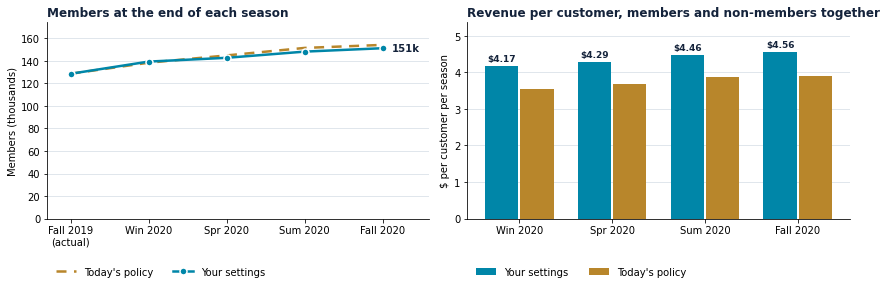

In [6]:
tu.plot(ctx, mine)

### Which settings bring in the most?

Every joining and member discount at your base price and offer share, ranked by four-season revenue per customer. "Next 4 seasons" is the same setting run for four more seasons: a setting that gains now by losing members shows up there.

In [7]:
tu.best_settings(ctx, BASE_PRICE, SHARE_OFFERED)

Top 10 of 36 settings at a $12 base with 25% of non-members offered. Today's policy: $14.98 per customer, 154,237 members at the end.


,Joining discount,Member discount,"Revenue per customer, 4 seasons",vs today,Members at the end,Members vs today,"Next 4 seasons, vs today"
1,$5,$0,$17.94,+19.7%,"142,861","-11,377",+15.9%
2,$4,$0,$17.68,+18.0%,"138,628","-15,609",+13.5%
3,$5,$1,$17.49,+16.7%,"151,289","-2,948",+15.5%
4,$3,$0,$17.43,+16.3%,"134,870","-19,368",+11.2%
5,$4,$1,$17.21,+14.9%,"146,596","-7,641",+12.6%
6,$2,$0,$17.19,+14.8%,"131,776","-22,461",+9.1%
7,$1,$0,$17.00,+13.4%,"129,305","-24,933",+7.3%
8,$3,$1,$16.94,+13.1%,"142,490","-11,748",+10.0%
9,$0,$0,$16.82,+12.3%,"127,296","-26,941",+5.8%
10,$2,$1,$16.70,+11.5%,"139,186","-15,051",+7.7%
